In [10]:
import numpy as np
import scipy as sp
import sympy as smp
import matplotlib.pyplot as plt
import random

import qiskit

import sys
sys.path.insert(0, '../../')

import oasis_dla
import pennylane as qp
from oasis_dla import I, X, Y, Z, H

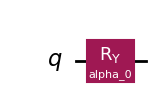

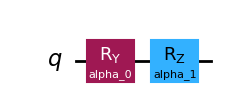

In [11]:
vqls_ry = oasis_dla.VQLS(qubits=1, ansatz_type=0, cost='direct')
vqls_rz = oasis_dla.VQLS(qubits=1, ansatz_type=1, cost='direct')

display(vqls_ry.ansatz.draw('mpl'))
display(vqls_rz.ansatz.draw('mpl'))

In [12]:
# iY = oasis_dla.SINGLE_QUBIT_GENERATORS['ry']
generators = oasis_dla.extract_generators(vqls_ry.ansatz)

dla_ry = oasis_dla.construct_dla(generators)
dla_ry

print(f"Generators: \n{generators}")
print(f"DLA: \n{dla_ry}")
# print(f"Pennylane DLA: \n{pennylane_dla}")
print(f"dim g_ry = {len(dla_ry)}")
print("----Fast-numerical-construction-algorithm----")
dla_ry_0 = oasis_dla.fast_numerical_construct_dla(generators)
dla_ry_0

print(f"Generators: \n{generators}")
print(f"DLA: \n{dla_ry_0}")
# print(f"Pennylane DLA: \n{pennylane_dla}")
print(f"dim g_ry = {len(dla_ry_0)}")

Generators: 
[array([[ 0. +0.j, -0.5+0.j],
       [ 0.5+0.j,  0. +0.j]])]
DLA: 
[array([[ 0. +0.j, -0.5+0.j],
       [ 0.5+0.j,  0. +0.j]])]
dim g_ry = 1
----Fast-numerical-construction-algorithm----
Generators: 
[array([[ 0. +0.j, -0.5+0.j],
       [ 0.5+0.j,  0. +0.j]])]
DLA: 
[array([[ 0. +0.j, -0.5+0.j],
       [ 0.5+0.j,  0. +0.j]])]
dim g_ry = 1


In [13]:
generators = oasis_dla.extract_generators(vqls_rz.ansatz)

dla_rz = oasis_dla.construct_dla(generators)
print(f"fast closure algorithm: DLA_rz = {dla_rz}")
print(f"dim g_rz = {len(dla_rz)}")


fast closure algorithm: DLA_rz = [array([[ 0. +0.j, -0.5+0.j],
       [ 0.5+0.j,  0. +0.j]]), array([[0.-0.5j, 0.+0.j ],
       [0.+0.j , 0.+0.5j]]), array([[-0.+0.j ,  0.-0.5j],
       [ 0.-0.5j,  0.+0.j ]])]
dim g_rz = 3


Closure test:

for two different dla's that I got, the one using the fast numerical generation paper and the one from the diagnosing BP paper, I'll compute closure to check which ones right

In [14]:
# fast numerical lie closure

dla = oasis_dla.fast_numerical_construct_dla(generators)
dla

vecs = [m.flatten() for m in dla]
mat = np.column_stack(vecs)
basis_rank = np.linalg.matrix_rank(mat)
print(f"Rank of basis vector matrix: {basis_rank}")

closure = dla.copy()
for g1 in dla:
    for g2 in dla:
        closure.append(oasis_dla.commutator(g1, g2))


vecs = [m.flatten() for m in closure]
new_mat = np.column_stack(vecs)
new_rank = np.linalg.matrix_rank(new_mat)
print(f"Rank of new vector matrix: {new_rank}")

Rank of basis vector matrix: 2
Rank of new vector matrix: 3


Now that we know we have the right DLA (which is all of su(2) itself), lets compute two things
- $P_\mathfrak{g}(\rho)$
- $Ann_\mathfrak{g}(\rho)$

where $\rho = |0\rangle \langle 0|$

In [15]:
ket0 = np.array([1, 0])
b = (np.ones(2) / np.sqrt(2)).reshape(-1, 1)
A = np.array([
    [1j, 0],
    [0, 1j]
])

rho = np.outer(ket0, ket0.conj())
O = A.conj().T @ (I - np.outer(b, b.conj())) @ A

# np.linalg.solve(A, b)
rho

array([[1, 0],
       [0, 0]])

In [16]:
# g-purity first

# hilbert-schmidt inner product
def inner_product(A, B):
    return np.trace(A.conj().T @ B)


print(f"ρ = \n{rho}")

# complexify the DLA first
dla_ry = np.array(dla_ry)
# i_dla_ry = dla_ry + 1j * dla_ry
# print(f"g + ig = \n{i_dla_ry}")

g_ry = dla_ry
# normalize the basis
g_ry = [B / np.sqrt(inner_product(B, B)) for B in g_ry]
# compute g-purity
def g_purity(g, H):
    gpurity = 0
    for B in g:
        gpurity += abs(inner_product(B, H))**2

    return gpurity

Pg_rho = g_purity(g_ry, rho)
Pg_O = g_purity(g_ry, O)
print(f"g-Purity of ρ: {Pg_rho}")
print(f"g-Purity of O: {Pg_O}")
print(f"dim_g = {len(dla_ry)}")

Var_l = (Pg_rho * Pg_O) / len(dla_ry)
print(f"Variance of the loss function: {Var_l}")

inner_product(g_ry[0], O)

ρ = 
[[1 0]
 [0 0]]
g-Purity of ρ: 0.0
g-Purity of O: 0.0
dim_g = 1
Variance of the loss function: 0.0


np.complex128(0j)

In [17]:

# complexify the DLA first
dla_rz = np.array(dla_rz)
# print(dla_rz)
# i_dla_rz = dla_rz + 1j * dla_rz
# print(i_dla_rz)

g_rz = dla_rz

print(f"g = \n{g_rz}")

# normalize the basis
g_rz = [B / np.sqrt(inner_product(B, B)) for B in g_rz]

Pg_rho = g_purity(g_rz, rho)
Pg_O = g_purity(g_rz, O)
print(f"g-Purity of ρ: {Pg_rho}")
print(f"g-Purity of O: {Pg_O}")
print(f"dim_g = {len(dla_rz)}")

Var_l = (Pg_rho * Pg_O) / len(dla_rz)
print(f"Variance of the loss function: {Var_l}")

# inner_product(i_dla_ry[0], O)

g = 
[[[ 0. +0.j  -0.5+0.j ]
  [ 0.5+0.j   0. +0.j ]]

 [[ 0. -0.5j  0. +0.j ]
  [ 0. +0.j   0. +0.5j]]

 [[-0. +0.j   0. -0.5j]
  [ 0. -0.5j  0. +0.j ]]]
g-Purity of ρ: 0.4999999999999999
g-Purity of O: 0.4999999999999998
dim_g = 3
Variance of the loss function: 0.08333333333333327


In [19]:
# annihilator of rho in g

# get the matrix of all actions
actions = [g @ rho for g in dla_rz]
for a in actions:
    print(a,"\n")
M = np.column_stack([a.flatten() for a in actions])

nullspace = sp.linalg.null_space(M)
print(f"Nullspace: \n{nullspace}")

print(np.linalg.matrix_rank(M), nullspace.shape[1])

ci = nullspace.reshape(1, -1)[0]

ann_g_basis = [sum(c * g for c, g in zip(nullspace[:, k], dla_rz)) for k in range(nullspace.shape[1])]
print(f"Ann_g basis: \n{ann_g_basis}")

# from ann_g get the orthogonal complement using the Hilbert-Schmidt inner product to get g/h



[[-0. +0.j -0. +0.j]
 [ 0.5+0.j  0. +0.j]] 

[[0.-0.5j 0.+0.j ]
 [0.+0.j  0.+0.j ]] 

[[0.+0.j  0.+0.j ]
 [0.-0.5j 0.+0.j ]] 

Nullspace: 
[[0.70710678-0.j        ]
 [0.        -0.j        ]
 [0.        -0.70710678j]]
2 1
Ann_g basis: 
[array([[ 0.        +0.j, -0.70710678+0.j],
       [ 0.        +0.j,  0.        +0.j]])]
